# V2 추천 모델 평가 결과 시각화

## 1. 시각화 목적

Content-based Filtering과 Item-based KNN의 최종 테스트 성능 및 하이퍼파라미터 탐색 결과를 시각적으로 비교함.

## 2. 데이터 출처

`evaluation/results/`에 저장된 V2 평가 CSV를 사용함.

- `final_model_comparison_v2.csv`: 최종 테스트 성능
- `hyperparameter_results_v2.csv`: 하이퍼파라미터 검증 성능

추천 모델을 재학습하지 않고 저장된 평가 결과를 시각화함.

## 3. 시각화 항목

1. Baseline 및 Tuned 모델의 Hit Rate@10 비교
2. Content-based 하이퍼파라미터별 Hit Rate@10 비교
3. Item-based KNN Shrinkage별 Hit Rate@10 비교

그래프는 `evaluation/figures/`에 PNG 형식으로 저장함.

In [1]:
# 1. 평가 결과 CSV 불러오기
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 프로젝트 루트와 evaluation 폴더 모두 지원
if (Path.cwd() / "evaluation" / "results").is_dir():
    eval_dir = Path.cwd() / "evaluation"
elif (Path.cwd() / "results").is_dir():
    eval_dir = Path.cwd()
else:
    raise FileNotFoundError(
        "evaluation/results 폴더를 찾을 수 없습니다."
    )

results_dir = eval_dir / "results"
figures_dir = eval_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

final_df = pd.read_csv(
    results_dir / "final_model_comparison_v2.csv"
)
hyper_df = pd.read_csv(
    results_dir / "hyperparameter_results_v2.csv"
)

print("최종 평가 데이터:", final_df.shape)
print("하이퍼파라미터 실험 데이터:", hyper_df.shape)
print("그래프 저장 폴더:", figures_dir.resolve())

display(final_df.head())
display(hyper_df.head())

최종 평가 데이터: (8, 10)
하이퍼파라미터 실험 데이터: (25, 11)
그래프 저장 폴더: C:\Users\sumin\perfume-recommender\evaluation\figures


,evaluation_type,model,users,hits,hit_rate_at_10,precision_at_10,recall_at_10,coverage,avg_recommendations,candidate_count
0,candidate_eligible,Content-based Baseline,300,14,0.046667,0.004667,0.046667,0.980000,9.800000,738
1,candidate_eligible,Content-based Tuned,300,19,0.063333,0.006333,0.063333,0.990000,9.900000,738
2,candidate_eligible,Item-based KNN Baseline,300,16,0.053333,0.005333,0.053333,0.973333,9.253333,738
3,candidate_eligible,Item-based KNN Tuned,300,17,0.056667,0.005667,0.056667,0.973333,9.253333,738
4,all_relevant,Content-based Baseline,315,14,0.044444,0.004444,0.044444,0.980952,9.809524,738


,model,brand_weight,like_threshold,shrinkage,users,hits,hit_rate_at_10,precision_at_10,recall_at_10,coverage,avg_recommendations
0,Content-based,0.5,6.0,NaN,217,13,0.059908,0.005991,0.059908,0.995392,9.953917
1,Content-based,0.5,8.0,NaN,217,13,0.059908,0.005991,0.059908,0.949309,9.493088
2,Content-based,0.2,6.0,NaN,217,12,0.055300,0.005530,0.055300,0.995392,9.953917
3,Content-based,0.3,6.0,NaN,217,12,0.055300,0.005530,0.055300,0.995392,9.953917
4,Content-based,0.5,7.0,NaN,217,12,0.055300,0.005530,0.055300,0.981567,9.815668


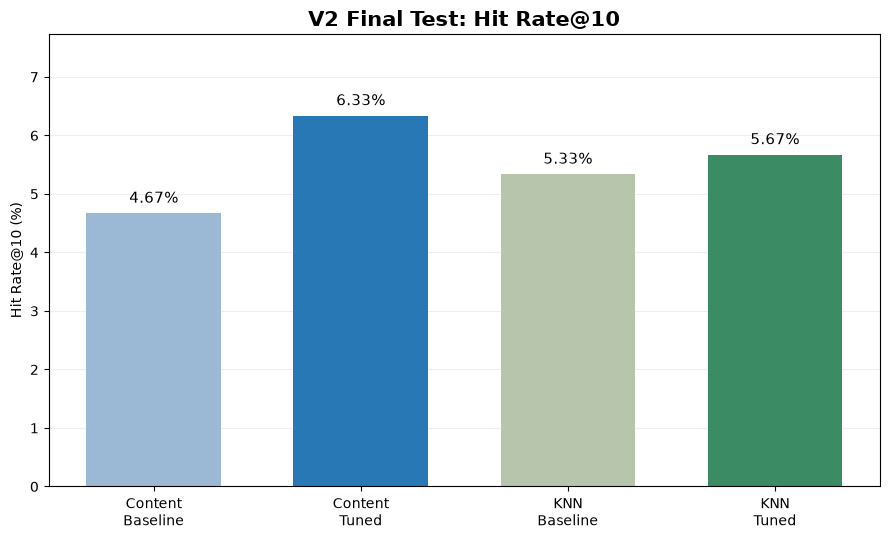

최종 성능 비교 그래프 저장 완료


In [2]:
# 2. Baseline vs Tuned 최종 Hit Rate@10
main_results = final_df.loc[
    final_df["evaluation_type"] == "candidate_eligible"
].copy()

model_order = [
    "Content-based Baseline",
    "Content-based Tuned",
    "Item-based KNN Baseline",
    "Item-based KNN Tuned"
]

main_results = main_results.set_index("model").loc[
    model_order
].reset_index()

labels = [
    "Content\nBaseline",
    "Content\nTuned",
    "KNN\nBaseline",
    "KNN\nTuned"
]

values = main_results["hit_rate_at_10"].to_numpy() * 100
colors = ["#9BB9D4", "#2878B5", "#B8C5AD", "#3B8B65"]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    labels,
    values,
    color=colors,
    width=0.65
)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "V2 Final Test: Hit Rate@10",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Hit Rate@10 (%)")
ax.set_ylim(0, max(values) * 1.22)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    figures_dir / "final_hit_rate_v2.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("최종 성능 비교 그래프 저장 완료")

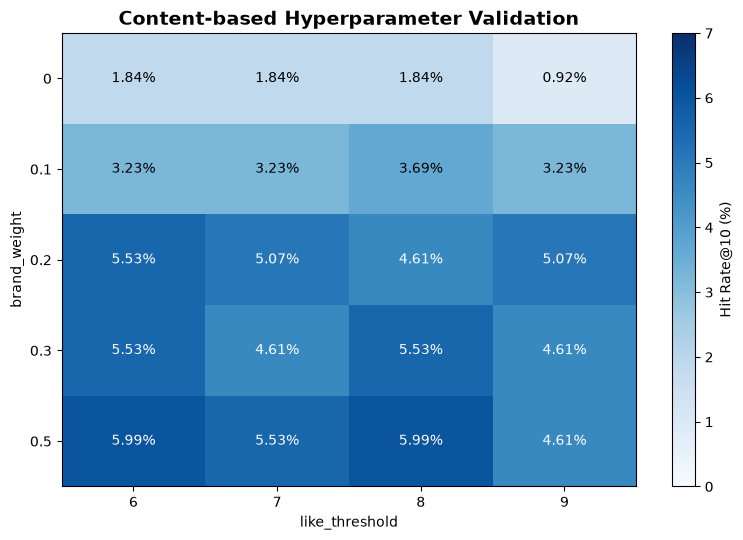

Content-based 히트맵 저장 완료


In [3]:
# 3. Content-based 하이퍼파라미터 히트맵
content_results = hyper_df.loc[
    hyper_df["model"] == "Content-based"
].copy()

pivot = content_results.pivot(
    index="brand_weight",
    columns="like_threshold",
    values="hit_rate_at_10"
) * 100

pivot = pivot.sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(8, 5.5))

im = ax.imshow(
    pivot.values,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=max(7, pivot.max().max())
)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([
    f"{int(x)}" for x in pivot.columns
])

ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([
    f"{x:g}" for x in pivot.index
])

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        value = pivot.iloc[i, j]
        ax.text(
            j, i,
            f"{value:.2f}%",
            ha="center",
            va="center",
            color="white" if value >= 4 else "black"
        )

ax.set_title(
    "Content-based Hyperparameter Validation",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("like_threshold")
ax.set_ylabel("brand_weight")

fig.colorbar(
    im,
    ax=ax,
    label="Hit Rate@10 (%)"
)

fig.tight_layout()
fig.savefig(
    figures_dir / "content_hyperparameter_v2.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Content-based 히트맵 저장 완료")

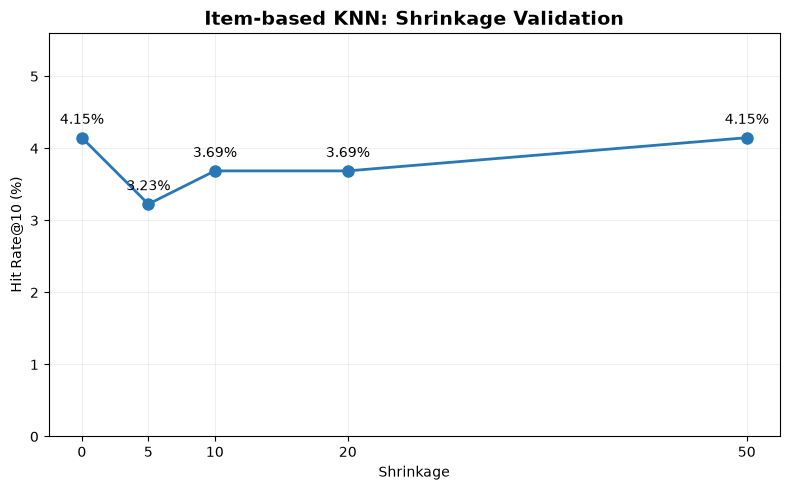

KNN Shrinkage 그래프 저장 완료


In [4]:
# 4. Item-based KNN Shrinkage별 검증 성능
knn_results = hyper_df.loc[
    hyper_df["model"] == "Item-based KNN"
].copy()

knn_results = knn_results.sort_values("shrinkage")

x = knn_results["shrinkage"].to_numpy()
y = knn_results["hit_rate_at_10"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    y,
    marker="o",
    markersize=8,
    linewidth=2,
    color="#2878B5"
)

for xv, yv in zip(x, y):
    ax.annotate(
        f"{yv:.2f}%",
        (xv, yv),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

ax.set_title(
    "Item-based KNN: Shrinkage Validation",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Shrinkage")
ax.set_ylabel("Hit Rate@10 (%)")
ax.set_xticks(x)
ax.set_ylim(0, max(y) * 1.35)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    figures_dir / "knn_shrinkage_v2.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("KNN Shrinkage 그래프 저장 완료")

## 4. 시각화 결과 분석

### 4.1 최종 테스트 성능

최종 테스트에서 Content-based Tuned 모델이 Hit Rate@10 6.33%로 가장 높은 성능을 기록함.

Content-based는 Baseline 4.67%에서 6.33%로 약 1.67%p 개선되었으며, Item-based KNN은 5.33%에서 5.67%로 약 0.33%p 개선됨.

### 4.2 Content-based 하이퍼파라미터

검증 데이터에서 `brand_weight=0.5`와 `like_threshold=6` 또는 `8` 조합이 공동 최고 Hit Rate@10 5.99%를 기록함.

최종 평가에는 이 중 `like_threshold=6`을 사용함.

### 4.3 Item-based KNN 하이퍼파라미터

검증 데이터에서 `shrinkage=0`과 `50`이 공동 최고 Hit Rate@10 4.15%를 기록함.

최종 평가에는 `shrinkage=0`을 사용함.

### 4.4 해석의 한계

- 최종 테스트 사용자 300명 중 Content-based Tuned 모델의 추천 성공은 19건임.
- 두 모델의 성능 개선 폭은 크지 않으며, 단일 데이터 분할에 따른 변동 가능성이 존재함.
- KNN의 평점 희소성 및 학습되지 않은 향수의 추천 불가능 문제가 존재함.
- 그래프는 관측된 평가 결과를 나타내며, 통계적 유의성을 입증하는 것은 아님.